# Data Understanding — the Lusa participant annotations

**Feeds:** the *Dataset* section of the Methodology and the opening of
Experiments & Results.

Every other notebook in this folder analyses **model output**. This one
analyses the **corpus itself**, read straight from `resources/` through the
same readers the pipeline uses (`src.reader`), so the numbers reported here
are the numbers the experiments were run against.

Three questions, one per section:

1. **How many participants are there?**
2. **What are the classes and how are they distributed?**
3. **Which words compose participant spans, and of what category?** —
   descriptive groundwork for the word-level (relaxed) evaluation.

The Portuguese and English corpora are parallel versions of the same
articles, so every table is reported side by side: a difference between the
two columns is a difference in *annotation*, not in content.

In [1]:
import sys

sys.path.insert(0, ".")        # _common
sys.path.insert(0, "../..")    # project root: src/, experiments/

import contextlib
import io
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import _common as c
from experiments.constants import (
    EXAMPLERS,
    SAMPLE_DOCS_IDS,
    WORD_CATEGORIES_EN,
    WORD_CATEGORIES_PT,
    word_to_category,
)
from src.reader import read_lusa, read_lusa_en

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 200)

## 0. Loading the corpus

The two languages arrive in different formats (Portuguese: plain text plus a
BRAT `.ann` file; English: an INCEpTION JSON export) and are normalised into
one representation by `src.reader`. Only the `Participant` annotations are
used. `read_lusa_en` prints one line per file, so its output is suppressed.

In [2]:
CORPUS_DIRS = {
    "portuguese": c.PROJECT_ROOT / "resources" / "lusa_news",
    "english": c.PROJECT_ROOT / "resources" / "lusa_en",
}

with contextlib.redirect_stdout(io.StringIO()):
    documents = {
        "portuguese": read_lusa(CORPUS_DIRS["portuguese"]),
        "english": read_lusa_en(CORPUS_DIRS["english"]),
    }

ids = {language: {d.id for d in docs} for language, docs in documents.items()}
for language, docs in documents.items():
    print(f"{language:<11} {len(docs):>4} documents")
print("\nIn Portuguese but not in English:", sorted(ids["portuguese"] - ids["english"]))
print("In English but not in Portuguese:", sorted(ids["english"] - ids["portuguese"]))

portuguese   117 documents
english      116 documents

In Portuguese but not in English: ['lusa_10']
In English but not in Portuguese: []


The corpus is used in three disjoint roles, fixed in
`experiments/constants.py`: the `exampler` article (`EXAMPLERS`) supplies the
one-shot example inside `*_exp` prompts and is never evaluated; the 19
`prompt_selection` articles (`SAMPLE_DOCS_IDS`) are where the eight prompt
variants are compared; everything else is the held-out `test` set.

In [3]:
def partition_of(doc_id: str, language: str) -> str:
    """The experimental role of a document (exampler / prompt_selection / test)."""
    if doc_id == EXAMPLERS[language]["participants"]:
        return "exampler"
    if doc_id in SAMPLE_DOCS_IDS[language]:
        return "prompt_selection"
    return "test"


PARTITION_ORDER = ["exampler", "prompt_selection", "test"]

doc_rows, participant_rows = [], []
for language, docs in documents.items():
    for doc in docs:
        partition = partition_of(doc.id, language)
        doc_rows.append({"language": language, "doc_id": doc.id, "partition": partition})
        for participant in doc.participants:
            participant_rows.append({
                "language": language,
                "doc_id": doc.id,
                "partition": partition,
                "participant_id": participant.id,
                "text": participant.text,
                "cls": c.normalize_type_label(
                    getattr(participant, "participant_type_domain", None)
                ),
            })

docs_df = pd.DataFrame(doc_rows)
participants = pd.DataFrame(participant_rows)

for frame in (docs_df, participants):
    frame["language"] = pd.Categorical(frame["language"], c.LANGUAGE_ORDER)
    frame["partition"] = pd.Categorical(frame["partition"], PARTITION_ORDER)

participants.head()

,language,doc_id,partition,participant_id,text,cls
0,portuguese,lusa_1,test,T24,A GNR,Org
1,portuguese,lusa_1,test,T42,bar,Fac
2,portuguese,lusa_1,test,T25,Corotelo,Pl_civil
3,portuguese,lusa_1,test,T23,concelho de São Brás de Alportel,Pl_civil
4,portuguese,lusa_1,test,T27,cerca de 50 pessoas,Per


## 1. How many participants?

`n_participants` counts **annotation instances**, not distinct entities: the
same person mentioned four times contributes four participants, because the
task is to recover every mention.

In [4]:
totals = pd.DataFrame({
    "n_documents": docs_df.groupby("language", observed=True).size(),
    "n_participants": participants.groupby("language", observed=True).size(),
}).T
print("Corpus totals:")
display(totals)

Corpus totals:


language,portuguese,english
n_documents,117,116
n_participants,3530,3502


In [5]:
by_partition = pd.DataFrame({
    "n_documents": docs_df.groupby(["language", "partition"], observed=True).size(),
    "n_participants": participants.groupby(["language", "partition"], observed=True).size(),
})
print("Per experimental partition:")
display(by_partition)

Per experimental partition:


n_documents  n_participants
language   partition                                    
portuguese exampler                    1              23
           prompt_selection           19             589
           test                       97            2918
english    exampler                    1              23
           prompt_selection           19             589
           test                       96            2890

Much of the corpus is repetition: a small set of surface forms accounts for a
large share of all mentions, and the two languages repeat the *same* forms.

In [6]:
print("Most repeated participant surface forms:")
display(
    participants.groupby(["language", "text"], observed=True).size().rename("n")
    .reset_index().sort_values(["language", "n"], ascending=[True, False])
    .groupby("language", observed=True).head(10).reset_index(drop=True)
)

Most repeated participant surface forms:


,language,text,n
0,portuguese,que,78
1,portuguese,a GNR,67
2,portuguese,fonte,53
3,portuguese,o local,50
4,portuguese,o homem,37
5,portuguese,a vítima,33
6,portuguese,comunicado,31
7,portuguese,Lusa,24
8,portuguese,A GNR,23
9,portuguese,onde,23


## 2. Participant classes and their distribution

Every participant carries a **type** from the `participant_type_domain`
attribute. The gold vocabulary is larger than the label set the
classification prompts offer: `src/meta.py` lists *Person, Organization,
Object, Location, Place (`Pl_<type>`), Nature, Facility* and *Other*, but the
corpus also uses `Veh` and `Path`, which no prompt ever names.

In [7]:
fine = (
    participants.groupby(["language", "cls"], observed=True, dropna=False)
    .size().rename("n").reset_index()
)
fine_wide = fine.pivot(index="cls", columns="language", values="n").fillna(0).astype(int)
fine_wide = fine_wide.loc[fine_wide.sum(axis=1).sort_values(ascending=False).index]

print(f"{fine_wide.shape[0]} distinct gold labels "
      f"(NaN = participant with no type attribute)")
print("\nAnnotated participants per type (fine-grained):")
display(fine_wide)

16 distinct gold labels (NaN = participant with no type attribute)

Annotated participants per type (fine-grained):


language,portuguese,english
cls,,
Per,1087,1079
Org,792,782
Obj,412,411
Loc,398,397
Other,266,266
Pl_civil,263,258
Nat,134,134
Fac,87,86
Pl_country,28,27


In [8]:
unreachable = [label for label in fine_wide.index
               if isinstance(label, str) and label not in set(c.PROMPT_CLASSES)]
print("Gold labels the classification prompt never offers:")
display(fine_wide.loc[unreachable])

Gold labels the classification prompt never offers:


language,portuguese,english
cls,,
Veh,11,11
Path,1,1


### Coarsened view

Models reproduce the generic `Loc` but essentially never the fine-grained
`Pl_*` subtypes, so the document-level analysis reports the **coarse** view in
which any `Pl_`-prefixed label collapses into `Loc`
(`_common.coarsen_label`). The same collapse is applied here so this prior
matches the one the class-level notebooks score against.

In [9]:
participants["cls_coarse"] = participants["cls"].map(c.coarsen_label)

coarse = (
    participants.groupby(["language", "cls_coarse"], observed=True, dropna=False)
    .size().rename("n").reset_index()
)
coarse_wide = coarse.pivot(index="cls_coarse", columns="language", values="n").fillna(0).astype(int)
coarse_wide = coarse_wide.loc[coarse_wide.sum(axis=1).sort_values(ascending=False).index]

print("Annotated participants per type (coarse):")
display(coarse_wide)

# The two untyped annotations are kept in the counts above, where their
# absence is the point, but excluded from the plotted label order below --
# an unnamed bar is not a class.
class_order = [label for label in coarse_wide.index if isinstance(label, str)]
fine_order = [label for label in fine_wide.index if isinstance(label, str)]

Annotated participants per type (coarse):


language,portuguese,english
cls_coarse,,
Per,1087,1079
Org,792,782
Loc,738,730
Obj,412,411
Other,266,266
Nat,134,134
Fac,87,86
Veh,11,11
NaN,2,2


Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\00_class_distribution.pdf


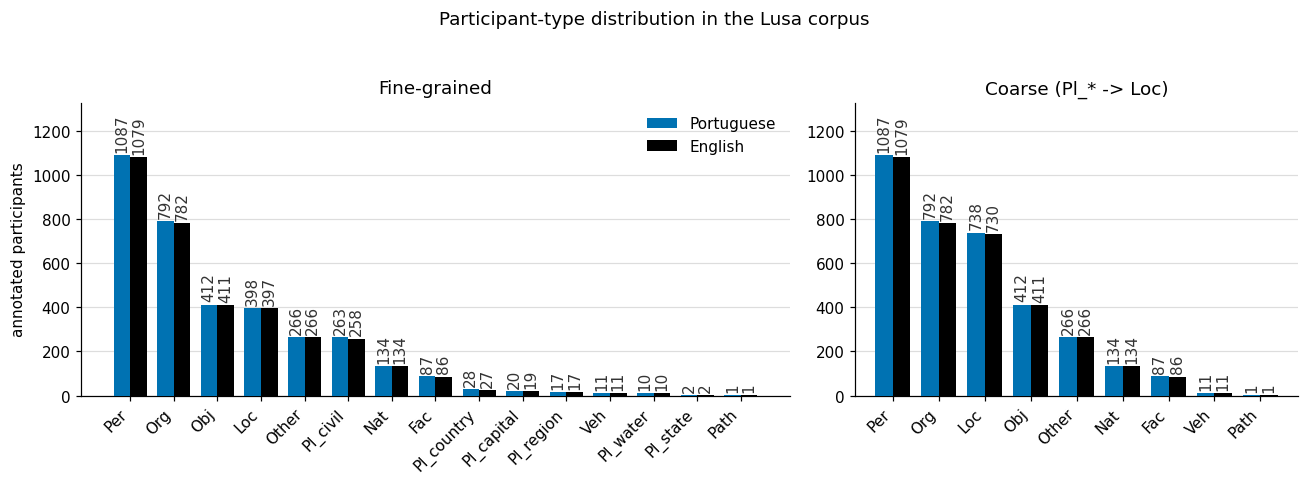

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2),
                         gridspec_kw={"width_ratios": [1.6, 1]})
width = 0.38
panels = [
    (axes[0], fine_wide.reindex(fine_order), fine_order, "Fine-grained"),
    (axes[1], coarse_wide.reindex(class_order), class_order, "Coarse (Pl_* -> Loc)"),
]
for ax, frame, order, title in panels:
    x = np.arange(len(order))
    for i, language in enumerate(c.LANGUAGE_ORDER):
        bars = ax.bar(x + (i - 0.5) * width, frame[language], width,
                      label=language.capitalize(), color=c.LANGUAGE_COLORS[language],
                      zorder=3)
        # Vertical labels: the fine-grained panel carries 30 bars, so
        # horizontal ones would overlap between the two languages.
        ax.bar_label(bars, padding=2, fontsize=10, rotation=90, color="#333333")
    ax.margins(y=0.22)  # headroom so the bar labels clear the frame
    ax.set_xticks(x)
    ax.set_xticklabels(order, rotation=45, ha="right")
    ax.set_title(title)
    c.style_axis(ax)
axes[0].set_ylabel("annotated participants")
axes[0].legend(frameon=False)
fig.suptitle("Participant-type distribution in the Lusa corpus", y=1.04)
c.save_fig(fig, "00_class_distribution")
plt.show()

The distribution is heavily skewed towards `Per`/`Org`/`Loc` and skewed
near-identically in the two languages, which is what the parallel corpus
guarantees: a Portuguese/English difference in attribute-level performance
cannot be explained by the models facing different class distributions.

### Is the prompt-selection subset representative?

The 19 prompt-selection articles are the basis on which each model's prompt
variant is chosen. If their class prior diverged from the test set, that
choice would not transfer.

In [11]:
partition_share = (
    participants[participants["partition"] != "exampler"]
    .groupby(["language", "partition", "cls_coarse"], observed=True)
    .size().rename("n").reset_index()
)
partition_share["share"] = partition_share["n"] / partition_share.groupby(
    ["language", "partition"], observed=True)["n"].transform("sum")

table = (
    partition_share.pivot_table(index="cls_coarse", columns=["language", "partition"],
                                values="share", fill_value=0.0, observed=False)
    .reindex(class_order)
)
print("Class share (%) by partition:")
display((table * 100).round(1))

gap = (
    table.xs("prompt_selection", axis=1, level="partition")
    - table.xs("test", axis=1, level="partition")
).abs()
print("\nLargest absolute prompt_selection - test gap, in percentage points:")
display((gap.max() * 100).round(1))

Class share (%) by partition:


language         portuguese                english      
partition  prompt_selection  test prompt_selection  test
cls_coarse                                              
Per                    32.7  30.6             32.7  30.6
Org                    22.8  22.4             22.8  22.3
Loc                    20.9  20.9             20.9  20.8
Obj                    12.9  11.2             12.9  11.3
Other                   7.1   7.7              7.1   7.8
Nat                     2.4   4.1              2.4   4.2
Fac                     1.2   2.6              1.2   2.6
Veh                     0.0   0.4              0.0   0.4
Path                    0.0   0.0              0.0   0.0


Largest absolute prompt_selection - test gap, in percentage points:


language
portuguese    2.0
english       2.0
dtype: float64

## 3. The words that compose participant spans

Span-level (strict) evaluation credits a prediction only on exact identity, so
a single extra leading article costs a false positive *and* a false negative.
The word-level (relaxed) metric exists to separate that kind of boundary
disagreement from a genuine miss, and it attributes each word to a **lexical
category** via `experiments.constants.word_to_category`. This section
describes the material that metric operates on.

Tokenisation mirrors `src.utils.tokenize` — strip punctuation, lowercase,
split on whitespace — reimplemented here only to avoid its debug printing.

The category taxonomy is read from `WORD_CATEGORIES_PT` / `WORD_CATEGORIES_EN`
as they currently stand, so this section re-renders itself whenever those
dictionaries change. Both dictionaries define the **same** category set, which
is what makes the Portuguese and English breakdowns comparable line by line.
`word_to_category` returns `Nao definido` for any word the dictionary does not
list; that bucket is shown as `Unlisted` and is a property of the dictionary,
not of the corpus. It is currently empty: both dictionaries cover their entire
span vocabulary.

In [12]:
CATEGORY_DICTS = {"portuguese": WORD_CATEGORIES_PT, "english": WORD_CATEGORIES_EN}
UNLISTED = "Unlisted"          # word_to_category's fallback for an unknown word
UNLISTED_COLOR = "#999999"
PALETTE = ["#E69F00", "#0072B2", "#009E73", "#D55E00", "#CC79A7",
           "#56B4E9", "#F0E442", "#8C6D31", "#7B3294", "#000000"]


def tokenize(text: str) -> list:
    """Mirrors src.utils.tokenize (punctuation stripped, lowercased, split)."""
    return re.sub(r"[^\w\s]", " ", str(text)).lower().split()


word_rows = []
for row in participants.itertuples(index=False):
    for token in tokenize(row.text):
        category = word_to_category(token, CATEGORY_DICTS[row.language])
        word_rows.append({
            "language": row.language,
            "doc_id": row.doc_id,
            "participant_id": row.participant_id,
            "word": token,
            "category": UNLISTED if category == "Nao definido" else category,
        })

words = pd.DataFrame(word_rows)
words["language"] = pd.Categorical(words["language"], c.LANGUAGE_ORDER)

# Colour is assigned once, over the whole corpus, so a category keeps the same
# colour in both panels -- the two dictionaries share a taxonomy, and a shared
# taxonomy that rendered in different colours per language would be unreadable.
# Order is by token frequency, with the residual Unlisted bucket forced last
# and always grey.
overall = words.groupby("category").size().sort_values(ascending=False)
named = [cat for cat in overall.index if cat != UNLISTED]
CATEGORY_COLORS = {cat: PALETTE[i % len(PALETTE)] for i, cat in enumerate(named)}
CATEGORY_COLORS[UNLISTED] = UNLISTED_COLOR
CATEGORY_ORDER = named + ([UNLISTED] if UNLISTED in overall.index else [])

category_order = {language: CATEGORY_ORDER for language in c.LANGUAGE_ORDER}
category_colors = {language: CATEGORY_COLORS for language in c.LANGUAGE_ORDER}

print(f"{len(words)} word tokens across {len(participants)} participant spans\n")
for language, dictionary in CATEGORY_DICTS.items():
    print(f"{language:<11} dictionary: {len(dictionary):>5} words, "
          f"{len(set(dictionary.values()))} categories")
    for category in category_order[language]:
        print(f"{'':<13}  - {category}")

17683 word tokens across 7032 participant spans

portuguese  dictionary:  1674 words, 10 categories
               - Articles & Determiners
               - Places & Facilities
               - Other Content Words
               - Generic Person Nouns
               - Prepositions & Connectives
               - Organizations & Institutions
               - Numbers & Quantities
               - Objects & Substances
               - Pronouns
               - Person Names
english     dictionary:  1628 words, 10 categories
               - Articles & Determiners
               - Places & Facilities
               - Other Content Words
               - Generic Person Nouns
               - Prepositions & Connectives
               - Organizations & Institutions
               - Numbers & Quantities
               - Objects & Substances
               - Pronouns
               - Person Names


Two counts of the same inventory: `n_tokens` is how many words inside
participant spans fall in each category — the surface a boundary error can
occur on — and `n_spans` is how many participant annotations contain at least
one such word, i.e. how many annotations a systematic policy on that category
would affect.

`Unlisted` is reported first: it measures how much of the corpus the
dictionary does not reach, and a large share there means the categories below
it describe only part of the picture.

In [13]:
tokens = words.groupby(["language", "category"], observed=True).size().rename("n_tokens")
spans = (
    words.drop_duplicates(subset=["language", "doc_id", "participant_id", "category"])
    .groupby(["language", "category"], observed=True).size().rename("n_spans")
)
category_table = pd.concat([tokens, spans], axis=1).reset_index()
category_table["pct_tokens"] = (
    100 * category_table["n_tokens"]
    / category_table.groupby("language", observed=True)["n_tokens"].transform("sum")
).round(1)
category_table = (
    category_table
    .sort_values(["language", "n_tokens"], ascending=[True, False])
    .reset_index(drop=True)
)

listed = category_table[category_table["category"] != UNLISTED]
coverage = (
    100 * listed.groupby("language", observed=True)["n_tokens"].sum()
    / category_table.groupby("language", observed=True)["n_tokens"].sum()
).round(1)
print("Share of span word tokens the dictionary categorises (%):")
display(coverage)
print("Words inside participant spans, by lexical category:")
display(category_table)

Share of span word tokens the dictionary categorises (%):


language
portuguese    100.0
english       100.0
Name: n_tokens, dtype: float64

Words inside participant spans, by lexical category:


,language,category,n_tokens,n_spans,pct_tokens
0,portuguese,Articles & Determiners,2147,2099,23.4
1,portuguese,Places & Facilities,1423,1038,15.5
2,portuguese,Prepositions & Connectives,1142,900,12.4
3,portuguese,Other Content Words,1115,829,12.1
4,portuguese,Generic Person Nouns,905,896,9.9
5,portuguese,Organizations & Institutions,869,741,9.5
6,portuguese,Numbers & Quantities,654,371,7.1
7,portuguese,Objects & Substances,501,433,5.5
8,portuguese,Pronouns,220,220,2.4
9,portuguese,Person Names,210,144,2.3


Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\00_word_categories.pdf


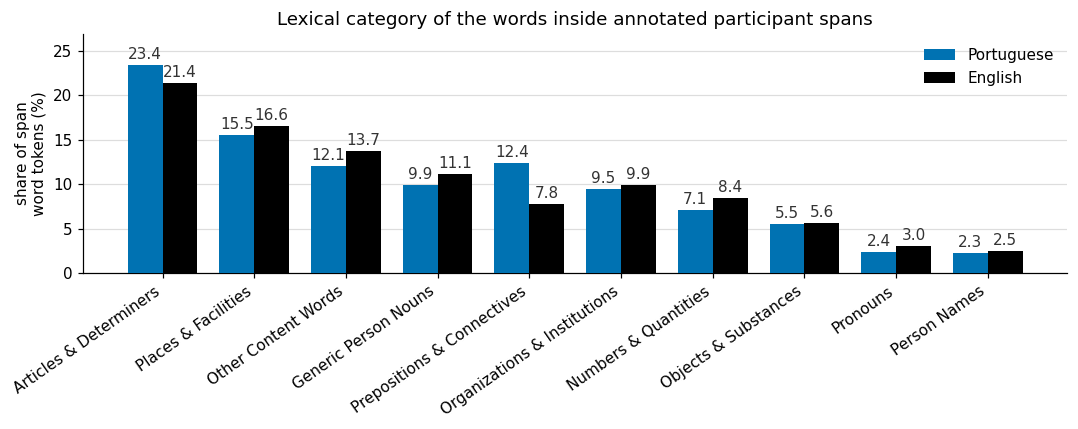

In [21]:
order = [cat for cat in CATEGORY_ORDER if cat != UNLISTED]
wide = (
    category_table.pivot(index="category", columns="language", values="pct_tokens")
    .reindex(order).fillna(0)
)
x = np.arange(len(order))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 4))
for i, language in enumerate(c.LANGUAGE_ORDER):
    bars = ax.bar(x + (i - 0.5) * width, wide[language], width,
                  label=language.capitalize(), color=c.LANGUAGE_COLORS[language],
                  zorder=3)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=10, color="#333333")
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=35, ha="right")
ax.set_ylabel("share of span\nword tokens (%)")
ax.set_title("Lexical category of the words inside annotated participant spans")
ax.margins(y=0.15)
ax.legend(frameon=False)
c.style_axis(ax)
c.save_fig(fig, "00_word_categories")
plt.show()

### The most frequent words

Which words actually fill participant spans, and of what kind. Bars are
coloured by lexical category, with one colour per category across both
panels.

In [15]:
frequent = (
    words.groupby(["language", "word", "category"], observed=True).size().rename("n")
    .reset_index().sort_values(["language", "n"], ascending=[True, False])
)
print("Most frequent words inside participant spans:")
display(frequent.groupby("language", observed=True).head(12).reset_index(drop=True))

Most frequent words inside participant spans:


,language,word,category,n
0,portuguese,o,Articles & Determiners,755
1,portuguese,de,Prepositions & Connectives,734
2,portuguese,a,Articles & Determiners,666
3,portuguese,um,Articles & Determiners,214
4,portuguese,os,Articles & Determiners,167
5,portuguese,homem,Generic Person Nouns,150
6,portuguese,gnr,Organizations & Institutions,122
7,portuguese,uma,Articles & Determiners,120
8,portuguese,anos,Numbers & Quantities,107
9,portuguese,da,Prepositions & Connectives,106


Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\00_top_words.pdf


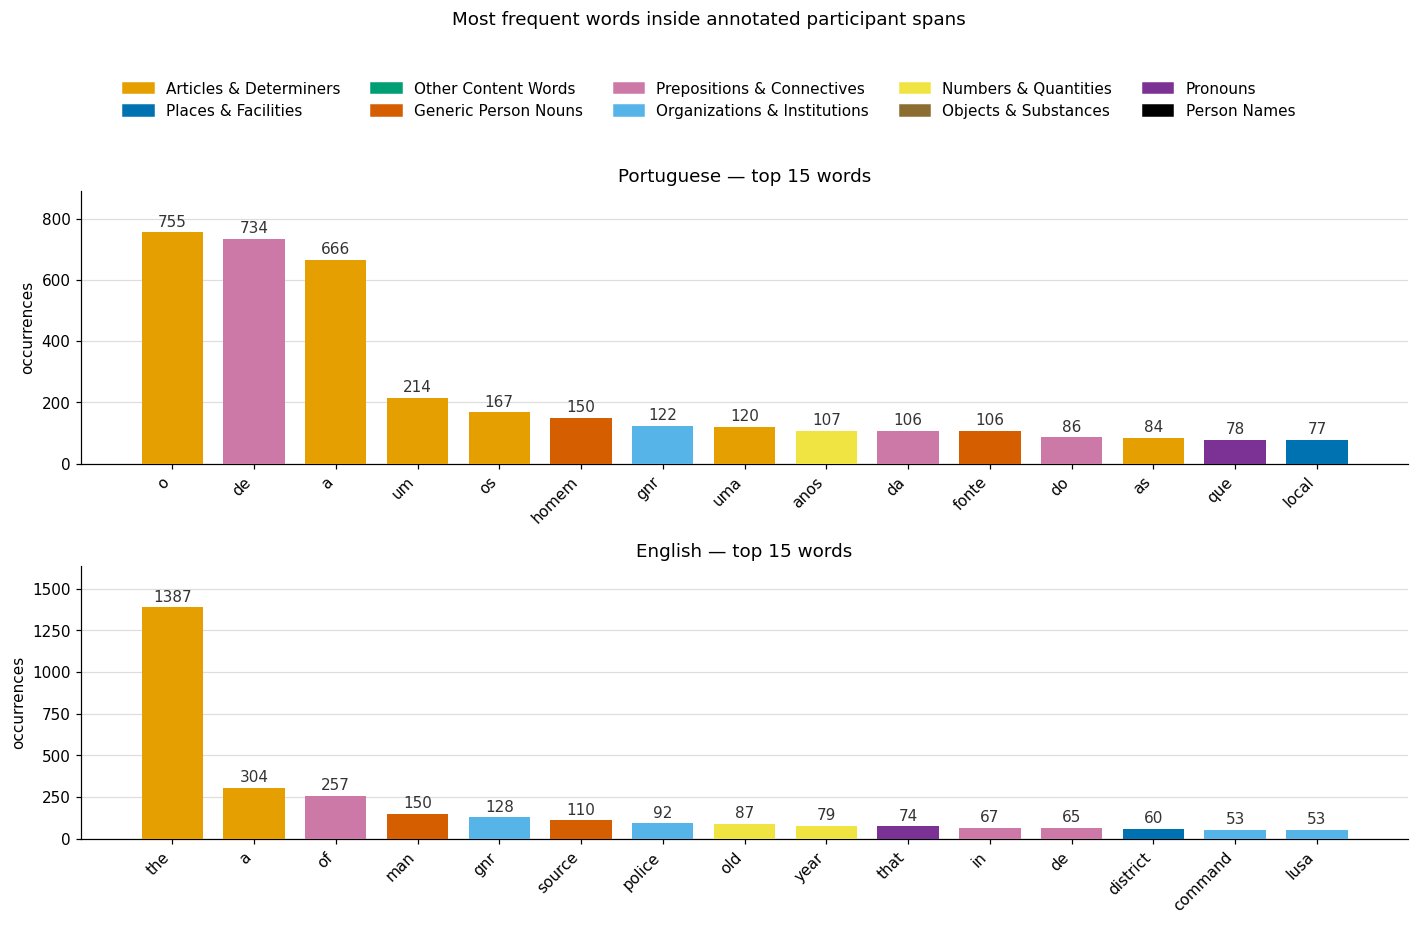

In [22]:
TOP_N = 15

fig, axes = plt.subplots(2, 1, figsize=(13, 7.4))
for ax, language in zip(axes, c.LANGUAGE_ORDER):
    top = frequent[frequent["language"] == language].head(TOP_N)
    colors = category_colors[language]
    x = np.arange(len(top))
    bars = ax.bar(x, top["n"], 0.75,
                  color=[colors[cat] for cat in top["category"]], zorder=3)
    ax.bar_label(bars, padding=2, fontsize=10, color="#333333")
    ax.set_xticks(x)
    ax.set_xticklabels(top["word"], rotation=45, ha="right")
    ax.set_title(f"{language.capitalize()} — top {TOP_N} words")
    ax.set_ylabel("occurrences")
    ax.margins(y=0.18)  # headroom so the bar labels clear the frame
    c.style_axis(ax)

# One legend for the figure: both panels use the same categories and colours.
handles = [plt.Rectangle((0, 0), 1, 1, color=CATEGORY_COLORS[cat])
           for cat in CATEGORY_ORDER]
fig.legend(handles, CATEGORY_ORDER, frameon=False, ncol=5,
           loc="upper center", bbox_to_anchor=(0.5, 1.06), fontsize=10)
fig.suptitle("Most frequent words inside annotated participant spans", y=1.13)
c.save_fig(fig, "00_top_words")
plt.show()

### How concentrated is the vocabulary?

The category shares above are driven by a very small number of word types. The
table below reports how much of the span text the most frequent words account
for, and how much of the vocabulary appears exactly once.

In [17]:
concentration = []
for language in c.LANGUAGE_ORDER:
    counts = frequent[frequent["language"] == language]["n"]
    total = counts.sum()
    row = {"language": language, "vocabulary": len(counts)}
    for n in (1, 5, 15, 50):
        row[f"top{n}_%_of_tokens"] = round(100 * counts.head(n).sum() / total, 1)
    row["hapax_%_of_vocabulary"] = round(100 * (counts == 1).sum() / len(counts), 1)
    concentration.append(row)
concentration = pd.DataFrame(concentration).set_index("language")
print("Concentration of the span vocabulary:")
display(concentration)

Concentration of the span vocabulary:


,vocabulary,top1_%_of_tokens,top5_%_of_tokens,top15_%_of_tokens,top50_%_of_tokens,hapax_%_of_vocabulary
language,,,,,,
portuguese,1674,8.2,27.6,38.9,51.9,50.5
english,1628,16.3,26.2,34.9,48.2,50.0


### Exporting the span vocabulary

The cell below writes **every distinct word appearing in a participant span**
to one plain-text file per language, frequency-ordered — not only the
`Unlisted` residue. That is deliberate: rebuilding a dictionary from the
residue alone silently drops the words it already covered, which is how
`WORD_CATEGORIES_EN` came to be missing `the`, `a` and `of`. Re-categorising
the complete vocabulary in one pass cannot lose an entry.

The `n_unlisted` column of the summary is the part the current dictionary does
not reach, and is the only figure that should shrink as the dictionaries
improve.

In [18]:
vocabulary = (
    words.groupby(["language", "word"], observed=True).size().rename("n")
    .reset_index().sort_values(["language", "n", "word"], ascending=[True, False, True])
)
unlisted_words = {
    language: set(group.loc[group["category"] == UNLISTED, "word"])
    for language, group in words.groupby("language", observed=True)
}

for language in c.LANGUAGE_ORDER:
    subset = vocabulary[vocabulary["language"] == language]
    path = c.HERE / f"content_words_{language}.txt"
    subset["word"].to_csv(path, index=False, header=False, encoding="utf-8")
    n_unlisted = subset["word"].isin(unlisted_words[language]).sum()
    print(f"{language:<11} {len(subset):>5} distinct words "
          f"({n_unlisted:>4} still unlisted), {subset['n'].sum():>5} tokens "
          f"-> {path.name}")

print()
print("Most frequent words still outside the dictionary:")
display(
    words[words["category"] == UNLISTED]
    .groupby(["language", "word"], observed=True).size().rename("n").reset_index()
    .sort_values(["language", "n"], ascending=[True, False])
    .groupby("language", observed=True).head(10).reset_index(drop=True)
)

portuguese   1674 distinct words (   0 still unlisted),  9186 tokens -> content_words_portuguese.txt
english      1628 distinct words (   0 still unlisted),  8497 tokens -> content_words_english.txt

Most frequent words still outside the dictionary:


,language,word,n


## Summary — the three takeaways

Written for reuse: everything the Experiments & Results chapter needs to
characterise the corpus before any score over it is read. The cell below
regenerates these numbers into `00_data_understanding_summary.md`, so the
figures quoted in the chapter cannot drift from the data.

**1. Documents and participants.** A parallel Portuguese/English corpus of
Lusa news articles — 117 PT and 116 EN documents (`lusa_10` has no English
version) carrying 3530 and 3502 annotated participants respectively, about 30
per document and never zero. The corpus splits into three disjoint roles: one
`exampler` article supplying the one-shot demonstration (23 participants), 19
`prompt_selection` articles (589), and 97 PT / 96 EN `test` articles (2918 /
2890). The two languages annotate the same articles, so any Portuguese/English
difference in results is a difference in *processing*, not in data.

**2. Class distribution.** Sixteen gold labels fine-grained, nine after
`Pl_*` collapses into `Loc`, and the distribution is heavily skewed: `Per`,
`Org` and `Loc` alone take roughly two thirds of all participants, while
`Veh`, `Path` and `Pl_state` are in the single or low double digits. The skew
is near-identical across the two languages, and the prompt-selection subset
reproduces the test set's prior to within 2 percentage points on every class.
Two consequences: attribute-level scores must be **macro-averaged** over types,
or the head classes carry the result; and a cross-lingual difference in
attribute performance cannot be blamed on different class distributions. Note
also that `Veh` and `Path` are annotated but never offered by the
classification prompt — unreachable by construction.

**3. Words and their categories.** Participant spans are built from a small,
heavily reused vocabulary: the 15 most frequent words account for 38.9% of all
Portuguese span tokens and 34.9% of English ones, while half the vocabulary
occurs exactly once. Function words dominate — articles and determiners alone
are 23.4% / 21.4% of span tokens and appear in roughly half of all
annotations. That is the material boundary disagreements are made of, and it
is why the strict/relaxed gap is read as disagreement about span edges rather
than as missed participants. The Portuguese preposition share (12.4% vs 7.8%)
is the one substantive asymmetry, and it is morphological: Portuguese contracts
preposition with article (`da`, `do`, `nas`) where English does not.

In [19]:
summary_path = c.HERE / "00_data_understanding_summary.md"

lines = ["# Data understanding — summary", ""]
lines += ["## 1. Documents and participants", ""]
lines += ["| language | partition | documents | participants |",
          "| --- | --- | ---: | ---: |"]
for (language, partition), row in by_partition.iterrows():
    lines.append(f"| {language} | {partition} | {row['n_documents']} | {row['n_participants']} |")
for language in c.LANGUAGE_ORDER:
    lines.append(f"| {language} | **all** | {totals.loc['n_documents', language]} "
                 f"| {totals.loc['n_participants', language]} |")

lines += ["", "## 2. Participant classes", "", "Fine-grained counts:", ""]
lines += ["| class | " + " | ".join(c.LANGUAGE_ORDER) + " |",
          "| --- | ---: | ---: |"]
for label, row in fine_wide.iterrows():
    label = "(no type attribute)" if not isinstance(label, str) else label
    lines.append("| " + label + " | "
                 + " | ".join(str(row[l]) for l in c.LANGUAGE_ORDER) + " |")

lines += ["", "Coarse counts (Pl_* -> Loc):", ""]
lines += ["| class | " + " | ".join(c.LANGUAGE_ORDER) + " |",
          "| --- | ---: | ---: |"]
for label, row in coarse_wide.iterrows():
    label = "(no type attribute)" if not isinstance(label, str) else label
    lines.append("| " + label + " | "
                 + " | ".join(str(row[l]) for l in c.LANGUAGE_ORDER) + " |")

top3 = coarse_wide.loc[class_order[:3]].sum() / coarse_wide.sum()
lines += ["", f"Share held by the three most frequent coarse classes: "
              + ", ".join(f"{l} {100 * top3[l]:.1f}%" for l in c.LANGUAGE_ORDER) + ".",
          "",
          f"Gold labels the classification prompt never offers: {', '.join(unreachable)}."]

lines += ["", "## 3. Words and lexical categories", "",
          "| category | " + " | ".join(f"{l} tokens | {l} %" for l in c.LANGUAGE_ORDER) + " |",
          "| --- | ---: | ---: | ---: | ---: |"]
for category in order:
    cells = []
    for language in c.LANGUAGE_ORDER:
        row = category_table[(category_table["language"] == language)
                             & (category_table["category"] == category)]
        cells += [str(int(row["n_tokens"].iloc[0])), f"{row['pct_tokens'].iloc[0]:.1f}"]
    lines.append(f"| {category} | " + " | ".join(cells) + " |")

lines += ["", "Vocabulary concentration:", "",
          "| language | vocabulary | top1 % | top5 % | top15 % | top50 % | hapax % |",
          "| --- | ---: | ---: | ---: | ---: | ---: | ---: |"]
for language, row in concentration.iterrows():
    lines.append(f"| {language} | {int(row['vocabulary'])} | {row['top1_%_of_tokens']} "
                 f"| {row['top5_%_of_tokens']} | {row['top15_%_of_tokens']} "
                 f"| {row['top50_%_of_tokens']} | {row['hapax_%_of_vocabulary']} |")

lines += ["", "Most frequent words:", ""]
for language in c.LANGUAGE_ORDER:
    top = frequent[frequent["language"] == language].head(15)
    words_str = ", ".join(f"{r.word} ({r.n}, {r.category})" for r in top.itertuples())
    lines += [f"- **{language}**: {words_str}", ""]

summary_path.write_text("\n".join(lines) + "\n", encoding="utf-8")
print(f"Wrote {summary_path} ({len(lines)} lines)")

Wrote C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\notebooks\results\00_data_understanding_summary.md (85 lines)
